In [2]:
import pandas as pd

file_path = r"C:\Users\anjal\OneDrive\Documents\Banking_analysis\Dataset\cleaned_data\LoanData_Cleaned.csv"

df = pd.read_csv(file_path, encoding="utf-8-sig")

print("Total records:", len(df))
print("Total columns:", len(df.columns))
print("Duplicate Application IDs:", df["Application_ID"].duplicated().sum())

Total records: 15000
Total columns: 26
Duplicate Application IDs: 0


In [3]:
%pip install mysql-connector-python pandas sqlalchemy

Note: you may need to restart the kernel to use updated packages.


In [4]:
import mysql.connector
import pandas as pd

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="anjali@565665",
    database="banking_loan_analytics"
)

print("Connected to MySQL successfully!")

Connected to MySQL successfully!


In [5]:
file_path = r"C:\Users\anjal\OneDrive\Documents\Banking_analysis\Dataset\cleaned_data\LoanData_Cleaned.csv"

df = pd.read_csv(file_path, encoding="utf-8-sig")

print("Total records:", len(df))
print("Total columns:", len(df.columns))
df.head()

Total records: 15000
Total columns: 26


,Application_ID,Application_Date,Age,Gender,Marital_Status,Dependents,Education,Employment_Status,Years_Employed,Applicant_Income,...,Savings,Collateral_Value,Loan_Amount,Loan_Term_Months,Loan_Purpose,Property_Area,Loan_Status,Credit_score_cleaned,Lone_Amount_Clean,Property_area_cleaned
0,LA100000,12-04-24 00:00,21,Male,Married,2,Not Graduate,Salaried,5,80700,...,47900,537700,212000.0,84,Debt Consolidation,Urban,Rejected,801,212000,Urban
1,LA100001,11-03-25 00:00,35,Male,Single,2,Not Graduate,Salaried,7,55900,...,106100,198600,92000.0,72,Debt Consolidation,Semiurban,Approved,760,92000,Semiurban
2,LA100002,10-05-26 00:00,30,Male,Widowed,0,Graduate,Business Owner,13,163300,...,273800,387100,723000.0,72,Vehicle,Rural,Approved,668,723000,Rural
3,LA100003,27-09-24 00:00,25,Female,Single,0,Graduate,Salaried,4,50800,...,227400,288400,506000.0,36,Home Purchase,Semiurban,Rejected,538,506000,Semiurban
4,LA100004,16-04-24 00:00,45,Male,Divorced,0,Not Graduate,Contract,6,54700,...,27900,276300,321000.0,60,Personal,Semiurban,Approved,748,321000,Semiurban


In [8]:
query = """
SELECT DATABASE() AS database_name;
"""

result = pd.read_sql(query, conn)
display(result)

C:\Users\anjal\AppData\Local\Temp\ipykernel_26968\624380163.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


,database_name
0,banking_loan_analytics


In [9]:
query = "SHOW TABLES;"

result = pd.read_sql(query, conn)
display(result)

C:\Users\anjal\AppData\Local\Temp\ipykernel_26968\1420756320.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


,Tables_in_banking_loan_analytics
0,loandata_cleaned


In [10]:
query = """
SELECT
    COUNT(*) AS total_applications
FROM loandata_cleaned;
"""

result = pd.read_sql(query, conn)
display(result)

C:\Users\anjal\AppData\Local\Temp\ipykernel_26968\4156157474.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


,total_applications
0,345


In [11]:
cursor = conn.cursor()

cursor.execute("SELECT COUNT(*) FROM banking_loan_analytics.loandata_cleaned")
print("MySQL row count:", cursor.fetchone()[0])

cursor.execute("SELECT * FROM banking_loan_analytics.loandata_cleaned LIMIT 5")
for row in cursor.fetchall():
    print(row)

cursor.close()

MySQL row count: 345
('LA100000', '12-04-24 00:00', 21, 'Male', 'Married', 2, 'Not Graduate', 'Salaried', 5, 80700, 0, 80700, 1, 2200, '801', 32.7, 47900, 537700, '212000', 84, 'Debt Consolidation', 'Urban', 'Rejected', '801', 212000, 'Urban')
('LA100001', '11-03-25 00:00', 35, 'Male', 'Single', 2, 'Not Graduate', 'Salaried', 7, 55900, 0, 55900, 0, 800, '760', 17.2, 106100, 198600, '92000', 72, 'Debt Consolidation', 'Semiurban', 'Approved', '760', 92000, 'Semiurban')
('LA100002', '10-05-26 00:00', 30, 'Male', 'Widowed', 0, 'Graduate', 'Business Owner', 13, 163300, 0, 163300, 2, 14700, '668', 75.0, 273800, 387100, '723000', 72, 'Vehicle', 'Rural', 'Approved', '668', 723000, 'Rural')
('LA100003', '27-09-24 00:00', 25, 'Female', 'Single', 0, 'Graduate', 'Salaried', 4, 50800, 41500, 92300, 1, 4000, '538', 52.0, 227400, 288400, '506000', 36, 'Home Purchase', 'Semiurban', 'Rejected', '538', 506000, 'Semiurban')
('LA100004', '16-04-24 00:00', 45, 'Male', 'Divorced', 0, 'Not Graduate', 'Contra

True

In [12]:
%pip install duckdb

   ---------------------------------------- 0.0/13.2 MB ? eta -:--:--
   - -------------------------------------- 0.5/13.2 MB 3.6 MB/s eta 0:00:04
   --- ------------------------------------ 1.3/13.2 MB 3.2 MB/s eta 0:00:04
   ------ --------------------------------- 2.1/13.2 MB 3.4 MB/s eta 0:00:04
   ------- -------------------------------- 2.6/13.2 MB 3.2 MB/s eta 0:00:04
   --------- ------------------------------ 3.1/13.2 MB 3.0 MB/s eta 0:00:04
   ----------- ---------------------------- 3.9/13.2 MB 3.0 MB/s eta 0:00:04
   ------------- -------------------------- 4.5/13.2 MB 3.0 MB/s eta 0:00:03
   --------------- ------------------------ 5.2/13.2 MB 3.1 MB/s eta 0:00:03
   ------------------ --------------------- 6.0/13.2 MB 3.1 MB/s eta 0:00:03
   ------------------- -------------------- 6.3/13.2 MB 3.0 MB/s eta 0:00:03
   ------------------- -------------------- 6.6/13.2 MB 3.0 MB/s eta 0:00:03
   --------------------- ------------------ 7.1/13.2 MB 2.8 MB/s eta 0:00:03
   ---

In [2]:
import duckdb

# Connect to an in-memory SQL database
con = duckdb.connect()

# Path to your cleaned CSV file
file_path = r"C:\Users\anjal\OneDrive\Documents\Banking_analysis\Dataset\cleaned_data\LoanData_Cleaned.csv"

# Check the CSV record count using SQL
query = f"""
SELECT COUNT(*) AS total_records
FROM read_csv_auto('{file_path}', header = true);
"""

result = con.execute(query).df()
display(result)

,total_records
0,15000


In [4]:
con.execute("""
CREATE OR REPLACE VIEW loan_data AS
SELECT *
FROM read_csv_auto(
    'C:/Users/anjal/OneDrive/Documents/Banking_analysis/Dataset/cleaned_data/LoanData_Cleaned.csv',
    header = true
);
""")

print("SQL view created successfully!")

SQL view created successfully!


In [5]:
display(con.execute("""
SELECT COUNT(*) AS total_applications
FROM loan_data;
""").df())

,total_applications
0,15000


In [10]:
query_02 = """
SELECT
    Application_ID,
    Age,
    Gender,
    Applicant_Income,
    Loan_Status
FROM loan_data
LIMIT 10;
"""

result = con.execute(query_02).df()
display(result)

,Application_ID,Age,Gender,Applicant_Income,Loan_Status
0,LA100000,21,Male,80700,Rejected
1,LA100001,35,Male,55900,Approved
2,LA100002,30,Male,163300,Approved
3,LA100003,25,Female,50800,Rejected
4,LA100004,45,Male,54700,Approved
5,LA100005,48,Female,74500,Rejected
6,LA100006,37,Female,71000,Rejected
7,LA100007,34,Female,50900,Rejected
8,LA100008,37,Female,113300,Approved
9,LA100009,29,Male,112100,Rejected


In [11]:
query_03 = """
SELECT COUNT(*) AS total_applications
FROM loan_data;
"""

result = con.execute(query_03).df()
display(result)

,total_applications
0,15000


In [12]:
query_03 = """
SELECT DISTINCT Loan_Status
FROM loan_data;
"""

result = con.execute(query_03).df()
display(result)

,Loan_Status
0,Rejected
1,Approved


In [13]:
query_04 = """
SELECT
    Application_ID,
    Age,
    Applicant_Income,
    Loan_Status
FROM loan_data
WHERE Loan_Status = 'Approved'
LIMIT 10;
"""

result = con.execute(query_04).df()
display(result)

,Application_ID,Age,Applicant_Income,Loan_Status
0,LA100001,35,55900,Approved
1,LA100002,30,163300,Approved
2,LA100004,45,54700,Approved
3,LA100008,37,113300,Approved
4,LA100010,42,44900,Approved
5,LA100011,21,50300,Approved
6,LA100012,25,53000,Approved
7,LA100014,41,104600,Approved
8,LA100018,28,95300,Approved
9,LA100024,38,179900,Approved


In [15]:
query_05 = """
SELECT
    Application_ID,
    Age,
    Applicant_Income,
    Loan_Amount,
    Loan_Status
FROM loan_data
WHERE Age BETWEEN 25 AND 40
LIMIT 10;
"""

result = con.execute(query_05).df()
display(result)

,Application_ID,Age,Applicant_Income,Loan_Amount,Loan_Status
0,LA100001,35,55900,92000,Approved
1,LA100002,30,163300,723000,Approved
2,LA100003,25,50800,506000,Rejected
3,LA100006,37,71000,252000,Rejected
4,LA100007,34,50900,236000,Rejected
5,LA100008,37,113300,203000,Approved
6,LA100009,29,112100,358000,Rejected
7,LA100012,25,53000,734000,Approved
8,LA100013,28,46300,404000,Rejected
9,LA100015,33,58500,702000,Rejected


In [16]:
query_06 = """
SELECT
    Application_ID,
    Applicant_Income,
    "Lone_Amount_Clean" AS Loan_Amount,
    Loan_Status
FROM loan_data
ORDER BY TRY_CAST("Lone_Amount_Clean" AS DOUBLE) DESC
LIMIT 10;
"""

result = con.execute(query_06).df()
display(result)

,Application_ID,Applicant_Income,Loan_Amount,Loan_Status
0,LA109012,46000,7500000,Rejected
1,LA102303,100100,7500000,Rejected
2,LA103591,99700,7500000,Approved
3,LA106546,43800,7500000,Rejected
4,LA105582,91400,7500000,Rejected
5,LA106979,435900,2398000,Rejected
6,LA104672,536900,2229000,Rejected
7,LA106667,31200,2177000,Approved
8,LA112379,357900,2096000,Approved
9,LA102272,278300,2093000,Rejected


In [19]:
query_07 = """
SELECT
    COUNT(*) AS total_applications,

    SUM(CASE
        WHEN Loan_Status = 'Approved' THEN 1
        ELSE 0
    END) AS approved_applications,

    SUM(CASE
        WHEN Loan_Status = 'Rejected' THEN 1
        ELSE 0
    END) AS rejected_applications,

    ROUND(
        100.0 * SUM(CASE
            WHEN Loan_Status = 'Approved' THEN 1
            ELSE 0
        END) / COUNT(*), 2
    ) AS approval_percentage,

    ROUND(
        100.0 * SUM(CASE
            WHEN Loan_Status = 'Rejected' THEN 1
            ELSE 0
        END) / COUNT(*), 2
    ) AS rejection_percentage

FROM loan_data;
"""

result = con.execute(query_07).df()
display(result)

,total_applications,approved_applications,rejected_applications,approval_percentage,rejection_percentage
0,15000,5782.0,9218.0,38.55,61.45


In [20]:
query_07 = """
SELECT
    SUM(TRY_CAST("Lone_Amount_Clean" AS DOUBLE))
        AS total_loan_amount,

    ROUND(
        AVG(TRY_CAST("Lone_Amount_Clean" AS DOUBLE)), 2
    ) AS average_loan_amount

FROM loan_data;
"""

result = con.execute(query_07).df()
display(result)

,total_loan_amount,average_loan_amount
0,6.056127e+09,403741.8


In [21]:
query_07 = """
SELECT
    SUM(TRY_CAST("Lone_Amount_Clean" AS DOUBLE))
        AS total_loan_amount,
    ROUND(
        AVG(TRY_CAST("Lone_Amount_Clean" AS DOUBLE)), 2
    ) AS average_loan_amount
FROM loan_data;
"""

result = con.execute(query_07).df()
display(result)

,total_loan_amount,average_loan_amount
0,6.056127e+09,403741.8


In [22]:
query_08 = """
SELECT
    ROUND(AVG(Applicant_Income), 2)
        AS average_applicant_income,
    MIN(Applicant_Income)
        AS minimum_applicant_income,
    MAX(Applicant_Income)
        AS maximum_applicant_income
FROM loan_data;
"""

result = con.execute(query_08).df()
display(result)

,average_applicant_income,minimum_applicant_income,maximum_applicant_income
0,75695.81,12000,1500000


In [23]:
query_09 = """
SELECT
    ROUND(
        AVG(TRY_CAST(Credit_Score_Cleaned AS DOUBLE)), 2
    ) AS average_credit_score,
    MIN(TRY_CAST(Credit_Score_Cleaned AS INTEGER))
        AS minimum_credit_score,
    MAX(TRY_CAST(Credit_Score_Cleaned AS INTEGER))
        AS maximum_credit_score
FROM loan_data;
"""

result = con.execute(query_09).df()
display(result)

,average_credit_score,minimum_credit_score,maximum_credit_score
0,697.95,421,850


In [24]:
query_10 = """
SELECT
    Loan_Status,
    COUNT(*) AS total_applications
FROM loan_data
GROUP BY Loan_Status
ORDER BY total_applications DESC;
"""

result = con.execute(query_10).df()
display(result)

,Loan_Status,total_applications
0,Rejected,9218
1,Approved,5782


In [25]:
query_11 = """
SELECT
    Property_area_cleaned AS property_area,
    COUNT(*) AS total_applications
FROM loan_data
GROUP BY Property_area_cleaned
ORDER BY total_applications DESC;
"""

result = con.execute(query_11).df()
display(result)

,property_area,total_applications
0,Urban,6057
1,Semiurban,5672
2,Rural,3271


In [26]:
query_12 = """
SELECT
    Gender,
    COUNT(*) AS total_applications,
    SUM(CASE WHEN Loan_Status = 'Approved'
        THEN 1 ELSE 0 END) AS approved_applications,
    ROUND(
        100.0 * SUM(CASE WHEN Loan_Status = 'Approved'
            THEN 1 ELSE 0 END) / COUNT(*), 2
    ) AS approval_percentage
FROM loan_data
GROUP BY Gender
ORDER BY approval_percentage DESC;
"""

display(con.execute(query_12).df())

,Gender,total_applications,approved_applications,approval_percentage
0,Male,9941,3833.0,38.56
1,Female,5059,1949.0,38.53


In [27]:
query_13 = """
SELECT
    Education,
    COUNT(*) AS total_applications,
    SUM(CASE WHEN Loan_Status = 'Approved'
        THEN 1 ELSE 0 END) AS approved_applications,
    ROUND(
        100.0 * SUM(CASE WHEN Loan_Status = 'Approved'
            THEN 1 ELSE 0 END) / COUNT(*), 2
    ) AS approval_percentage
FROM loan_data
GROUP BY Education
ORDER BY approval_percentage DESC;
"""

display(con.execute(query_13).df())

,Education,total_applications,approved_applications,approval_percentage
0,Graduate,10821,4337.0,40.08
1,Not Graduate,4179,1445.0,34.58


In [28]:
query_14 = """
SELECT
    Employment_Status,
    COUNT(*) AS total_applications,
    SUM(CASE WHEN Loan_Status = 'Approved'
        THEN 1 ELSE 0 END) AS approved_applications,
    ROUND(
        100.0 * SUM(CASE WHEN Loan_Status = 'Approved'
            THEN 1 ELSE 0 END) / COUNT(*), 2
    ) AS approval_percentage
FROM loan_data
GROUP BY Employment_Status
ORDER BY approval_percentage DESC;
"""

display(con.execute(query_14).df())

,Employment_Status,total_applications,approved_applications,approval_percentage
0,Salaried,7729,3077.0,39.81
1,Unknown,90,35.0,38.89
2,Business Owner,2096,790.0,37.69
3,Self-Employed,2730,1029.0,37.69
4,Unemployed,744,269.0,36.16
5,Contract,1611,582.0,36.13


In [29]:
query_15 = """
SELECT
    Property_area_cleaned AS property_area,
    COUNT(*) AS total_applications,
    SUM(CASE WHEN Loan_Status = 'Approved'
        THEN 1 ELSE 0 END) AS approved_applications,
    ROUND(
        100.0 * SUM(CASE WHEN Loan_Status = 'Approved'
            THEN 1 ELSE 0 END) / COUNT(*), 2
    ) AS approval_percentage
FROM loan_data
GROUP BY Property_area_cleaned
ORDER BY approval_percentage DESC;
"""

display(con.execute(query_15).df())

,property_area,total_applications,approved_applications,approval_percentage
0,Semiurban,5672,2202.0,38.82
1,Urban,6057,2346.0,38.73
2,Rural,3271,1234.0,37.73


In [30]:
query_16 = """
SELECT
    CASE
        WHEN Age < 25 THEN 'Under 25'
        WHEN Age BETWEEN 25 AND 34 THEN '25-34'
        WHEN Age BETWEEN 35 AND 44 THEN '35-44'
        WHEN Age BETWEEN 45 AND 54 THEN '45-54'
        ELSE '55 and above'
    END AS age_group,
    COUNT(*) AS total_applications,
    SUM(CASE WHEN Loan_Status = 'Approved'
        THEN 1 ELSE 0 END) AS approved_applications,
    ROUND(
        100.0 * SUM(CASE WHEN Loan_Status = 'Approved'
            THEN 1 ELSE 0 END) / COUNT(*), 2
    ) AS approval_percentage
FROM loan_data
WHERE Age IS NOT NULL
GROUP BY age_group
ORDER BY MIN(Age);
"""

display(con.execute(query_16).df())

,age_group,total_applications,approved_applications,approval_percentage
0,Under 25,1856,706.0,38.04
1,25-34,4794,1805.0,37.65
2,35-44,5389,2139.0,39.69
3,45-54,2508,981.0,39.11
4,55 and above,453,151.0,33.33


In [31]:
query_17 = """
SELECT
    CASE
        WHEN TRY_CAST(Credit_score_cleaned AS DOUBLE) < 600
            THEN 'Below 600'
        WHEN TRY_CAST(Credit_score_cleaned AS DOUBLE) < 700
            THEN '600-699'
        WHEN TRY_CAST(Credit_score_cleaned AS DOUBLE) < 750
            THEN '700-749'
        ELSE '750 and above'
    END AS credit_score_band,
    COUNT(*) AS total_applications,
    SUM(CASE WHEN Loan_Status = 'Approved'
        THEN 1 ELSE 0 END) AS approved_applications,
    ROUND(
        100.0 * SUM(CASE WHEN Loan_Status = 'Approved'
            THEN 1 ELSE 0 END) / COUNT(*), 2
    ) AS approval_percentage
FROM loan_data
WHERE TRY_CAST(Credit_score_cleaned AS DOUBLE) IS NOT NULL
GROUP BY credit_score_band
ORDER BY MIN(TRY_CAST(Credit_score_cleaned AS DOUBLE));
"""

display(con.execute(query_17).df())

,credit_score_band,total_applications,approved_applications,approval_percentage
0,Below 600,1417,358.0,25.26
1,600-699,6126,2108.0,34.41
2,700-749,3779,1559.0,41.25
3,750 and above,3678,1757.0,47.77


In [32]:
query_18 = """
SELECT
    CASE
        WHEN DTI_Ratio < 30 THEN 'Below 30'
        WHEN DTI_Ratio < 50 THEN '30-49.99'
        ELSE '50 and above'
    END AS dti_band,
    COUNT(*) AS total_applications,
    SUM(CASE WHEN Loan_Status = 'Approved'
        THEN 1 ELSE 0 END) AS approved_applications,
    ROUND(
        100.0 * SUM(CASE WHEN Loan_Status = 'Approved'
            THEN 1 ELSE 0 END) / COUNT(*), 2
    ) AS approval_percentage
FROM loan_data
WHERE DTI_Ratio IS NOT NULL
GROUP BY dti_band
ORDER BY MIN(DTI_Ratio);
"""

display(con.execute(query_18).df())

,dti_band,total_applications,approved_applications,approval_percentage
0,Below 30,3602,2699.0,74.93
1,30-49.99,2063,1197.0,58.02
2,50 and above,9335,1886.0,20.20


In [33]:
query_19 = """
WITH area_summary AS (
    SELECT
        Property_area_cleaned AS property_area,
        COUNT(*) AS total_applications,
        SUM(CASE WHEN Loan_Status = 'Approved'
            THEN 1 ELSE 0 END) AS approved_applications
    FROM loan_data
    GROUP BY Property_area_cleaned
)
SELECT
    property_area,
    total_applications,
    approved_applications,
    ROUND(
        100.0 * approved_applications / total_applications, 2
    ) AS approval_percentage
FROM area_summary
ORDER BY approval_percentage DESC;
"""

display(con.execute(query_19).df())

,property_area,total_applications,approved_applications,approval_percentage
0,Semiurban,5672,2202.0,38.82
1,Urban,6057,2346.0,38.73
2,Rural,3271,1234.0,37.73


In [34]:
query_20 = """
WITH purpose_summary AS (
    SELECT
        Loan_Purpose,
        COUNT(*) AS total_applications
    FROM loan_data
    GROUP BY Loan_Purpose
)
SELECT
    Loan_Purpose,
    total_applications,
    RANK() OVER (
        ORDER BY total_applications DESC
    ) AS purpose_rank
FROM purpose_summary
ORDER BY purpose_rank;
"""

display(con.execute(query_20).df())

,Loan_Purpose,total_applications,purpose_rank
0,Home Purchase,3755,1
1,Personal,2450,2
2,Vehicle,2388,3
3,Business,1994,4
4,Home Renovation,1758,5
5,Debt Consolidation,1510,6
6,Education,1145,7


In [36]:
query_22 = """
WITH dti_summary AS (
    SELECT
        CASE
            WHEN DTI_Ratio < 30 THEN 'Below 30'
            WHEN DTI_Ratio < 50 THEN '30-49.99'
            ELSE '50 and above'
        END AS dti_band,
        COUNT(*) AS total_applications,
        SUM(CASE WHEN Loan_Status = 'Rejected'
            THEN 1 ELSE 0 END) AS rejected_applications
    FROM loan_data
    WHERE DTI_Ratio IS NOT NULL
    GROUP BY dti_band
)
SELECT
    dti_band,
    total_applications,
    rejected_applications,
    ROUND(
        100.0 * rejected_applications / total_applications, 2
    ) AS rejection_percentage
FROM dti_summary
ORDER BY rejection_percentage DESC;
"""

display(con.execute(query_22).df())

,dti_band,total_applications,rejected_applications,rejection_percentage
0,50 and above,9335,7449.0,79.80
1,30-49.99,2063,866.0,41.98
2,Below 30,3602,903.0,25.07


In [37]:
query_23 = """
SELECT
    Loan_Status,
    COUNT(*) AS total_applications,
    ROUND(
        AVG(TRY_CAST("Lone_Amount_Clean" AS DOUBLE)), 2
    ) AS average_loan_amount,
    ROUND(
        MIN(TRY_CAST("Lone_Amount_Clean" AS DOUBLE)), 2
    ) AS minimum_loan_amount,
    ROUND(
        MAX(TRY_CAST("Lone_Amount_Clean" AS DOUBLE)), 2
    ) AS maximum_loan_amount
FROM loan_data
GROUP BY Loan_Status
ORDER BY average_loan_amount DESC;
"""

display(con.execute(query_23).df())

,Loan_Status,total_applications,average_loan_amount,minimum_loan_amount,maximum_loan_amount
0,Approved,5782,434769.63,20000.0,7500000.0
1,Rejected,9218,384279.56,20000.0,7500000.0


In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [39]:
%pip install pandas matplotlib seaborn duckdb

Note: you may need to restart the kernel to use updated packages.


In [40]:
df = con.execute("SELECT * FROM loan_data").df()

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (15000, 26)


,Application_ID,Application_Date,Age,Gender,Marital_Status,Dependents,Education,Employment_Status,Years_Employed,Applicant_Income,...,Savings,Collateral_Value,Loan_Amount,Loan_Term_Months,Loan_Purpose,Property_Area,Loan_Status,Credit_score_cleaned,Lone_Amount_Clean,Property_area_cleaned
0,LA100000,12-04-24,21,Male,Married,2,Not Graduate,Salaried,5,80700,...,47900,537700,212000,84,Debt Consolidation,Urban,Rejected,801,212000,Urban
1,LA100001,11-03-25,35,Male,Single,2,Not Graduate,Salaried,7,55900,...,106100,198600,92000,72,Debt Consolidation,Semiurban,Approved,760,92000,Semiurban
2,LA100002,10-05-26,30,Male,Widowed,0,Graduate,Business Owner,13,163300,...,273800,387100,723000,72,Vehicle,Rural,Approved,668,723000,Rural
3,LA100003,27-09-24,25,Female,Single,0,Graduate,Salaried,4,50800,...,227400,288400,506000,36,Home Purchase,Semiurban,Rejected,538,506000,Semiurban
4,LA100004,16-04-24,45,Male,Divorced,0,Not Graduate,Contract,6,54700,...,27900,276300,321000,60,Personal,Semiurban,Approved,748,321000,Semiurban


In [45]:
df["Loan_Status"].value_counts()

Loan_Status
Rejected    9218
Approved    5782
Name: count, dtype: int64

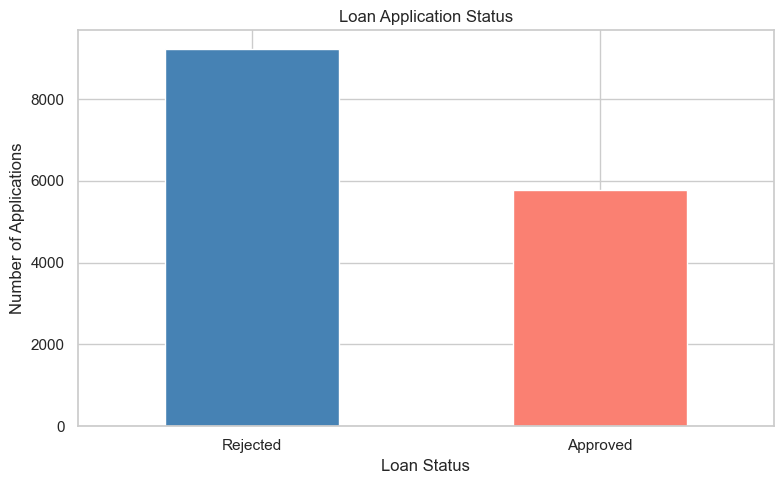

In [53]:
df["Loan_Status"].value_counts().plot(
    kind="bar", figsize=(8, 5), color=["steelblue", "salmon"],
    title="Loan Application Status"
)
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [47]:
df["Loan_Status"].value_counts(normalize=True).mul(100).round(2)

Loan_Status
Rejected    61.45
Approved    38.55
Name: proportion, dtype: float64

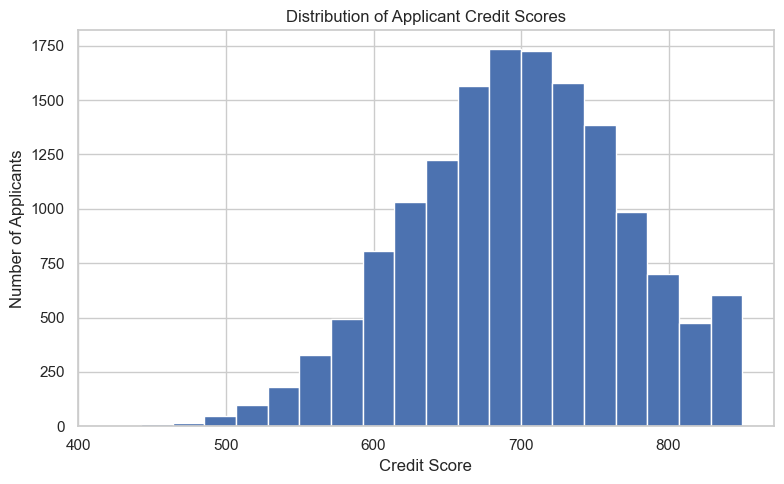

In [50]:
df["Credit_score_cleaned"].plot(
    kind="hist",
    bins=20,
    figsize=(8, 5),
    title="Distribution of Applicant Credit Scores"
)

plt.xlabel("Credit Score")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

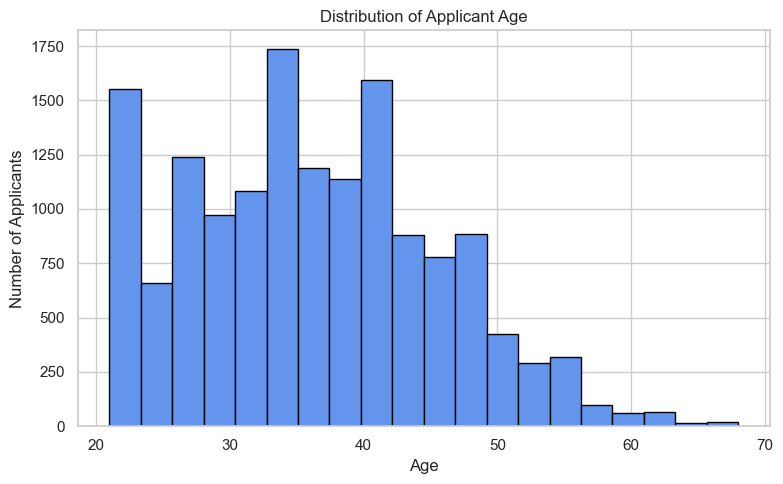

In [54]:
df["Age"].plot(
    kind="hist", bins=20, figsize=(8, 5),
    color="cornflowerblue", edgecolor="black",
    title="Distribution of Applicant Age"
)
plt.xlabel("Age")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

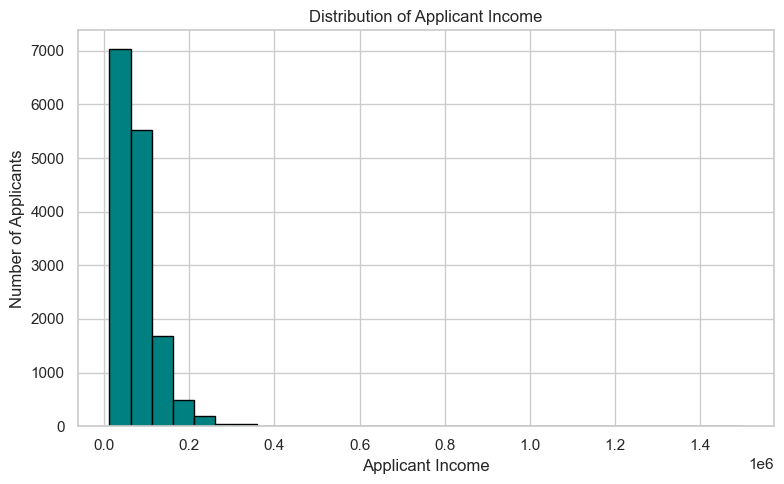

In [55]:
df["Applicant_Income"].dropna().plot(
    kind="hist", bins=30, figsize=(8, 5),
    color="teal", edgecolor="black",
    title="Distribution of Applicant Income"
)
plt.xlabel("Applicant Income")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

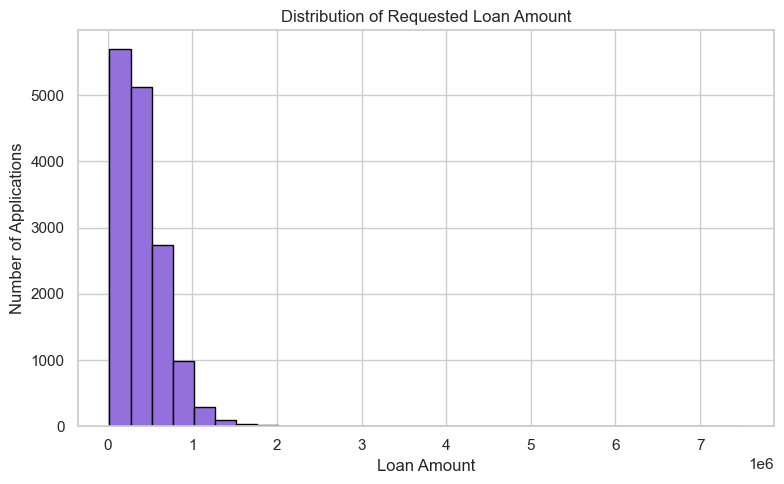

In [56]:
df["Lone_Amount_Clean"].dropna().plot(
    kind="hist", bins=30, figsize=(8, 5),
    color="mediumpurple", edgecolor="black",
    title="Distribution of Requested Loan Amount"
)
plt.xlabel("Loan Amount")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()

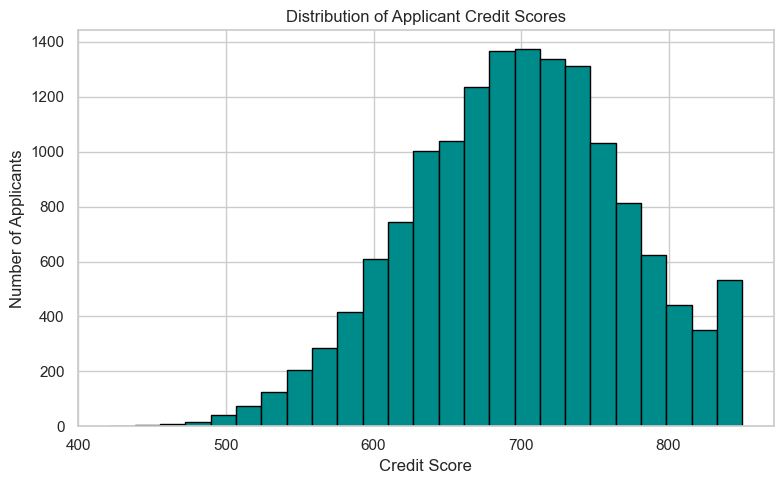

In [57]:
df["Credit_score_cleaned"].dropna().plot(
    kind="hist", bins=25, figsize=(8, 5),
    color="darkcyan", edgecolor="black",
    title="Distribution of Applicant Credit Scores"
)
plt.xlabel("Credit Score")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

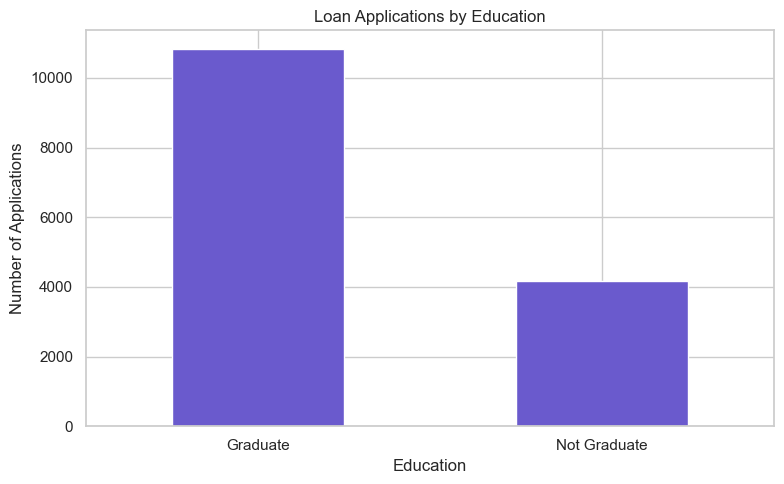

In [58]:
df["Education"].value_counts().plot(
    kind="bar", figsize=(8, 5),
    title="Loan Applications by Education",
    color="slateblue"
)
plt.xlabel("Education")
plt.ylabel("Number of Applications")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

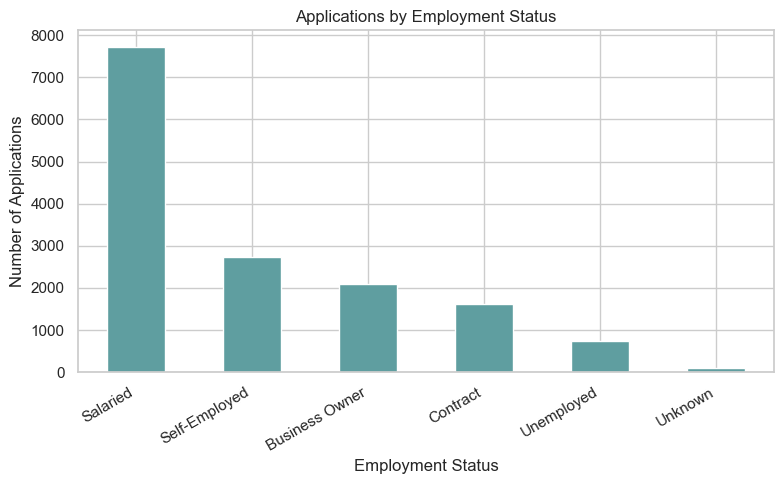

In [59]:
df["Employment_Status"].value_counts().plot(
    kind="bar", figsize=(8, 5),
    title="Applications by Employment Status",
    color="cadetblue"
)
plt.xlabel("Employment Status")
plt.ylabel("Number of Applications")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

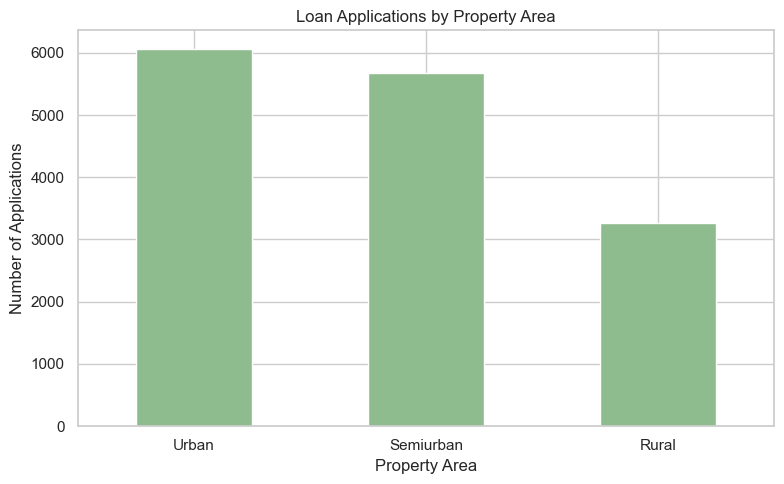

In [60]:
df["Property_area_cleaned"].value_counts().plot(
    kind="bar", figsize=(8, 5),
    title="Loan Applications by Property Area",
    color="darkseagreen"
)
plt.xlabel("Property Area")
plt.ylabel("Number of Applications")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

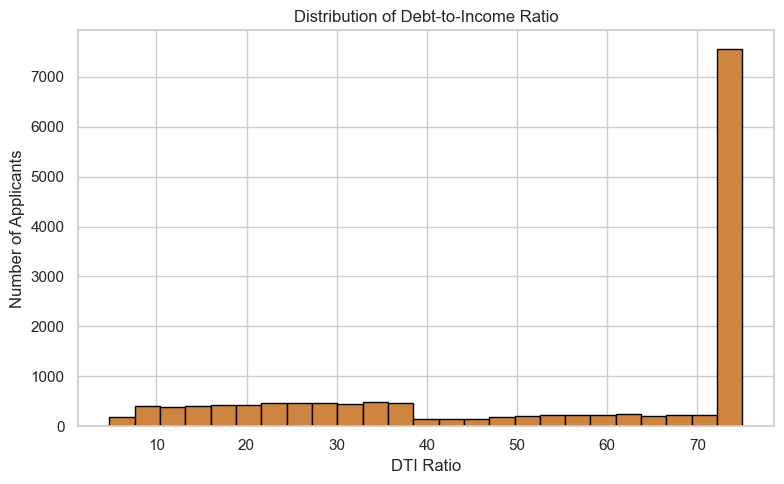

In [61]:
df["DTI_Ratio"].dropna().plot(
    kind="hist", bins=25, figsize=(8, 5),
    color="peru", edgecolor="black",
    title="Distribution of Debt-to-Income Ratio"
)
plt.xlabel("DTI Ratio")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

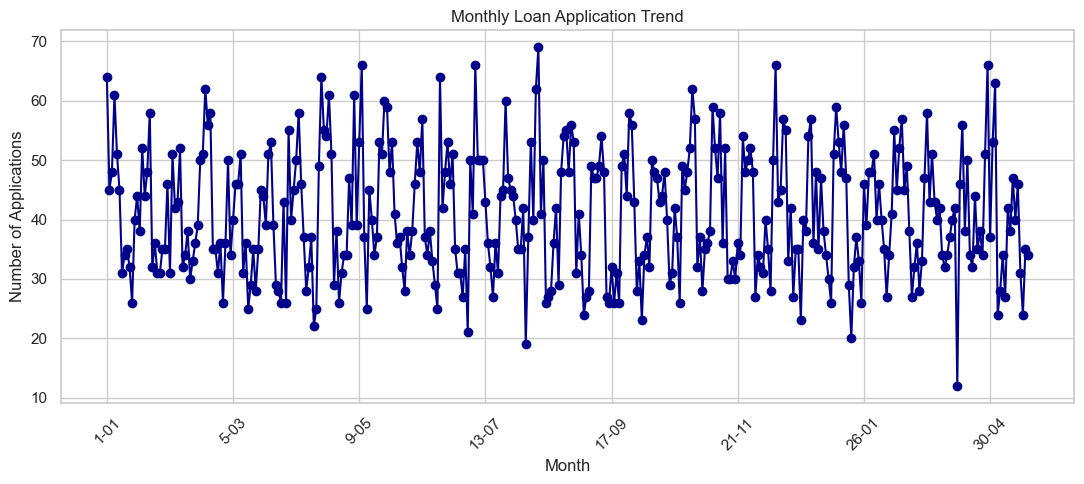

In [62]:
df["Parsed_Date"] = pd.to_datetime(
    df["Application_Date"],
    format="%d-%m-%y %H:%M",
    errors="coerce"
)

monthly_apps = (
    df.dropna(subset=["Parsed_Date"])
      .groupby(df["Parsed_Date"].dt.to_period("M"))
      .size()
)

monthly_apps.index = monthly_apps.index.astype(str)

monthly_apps.plot(
    kind="line", marker="o", figsize=(11, 5),
    title="Monthly Loan Application Trend",
    color="darkblue"
)
plt.xlabel("Month")
plt.ylabel("Number of Applications")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

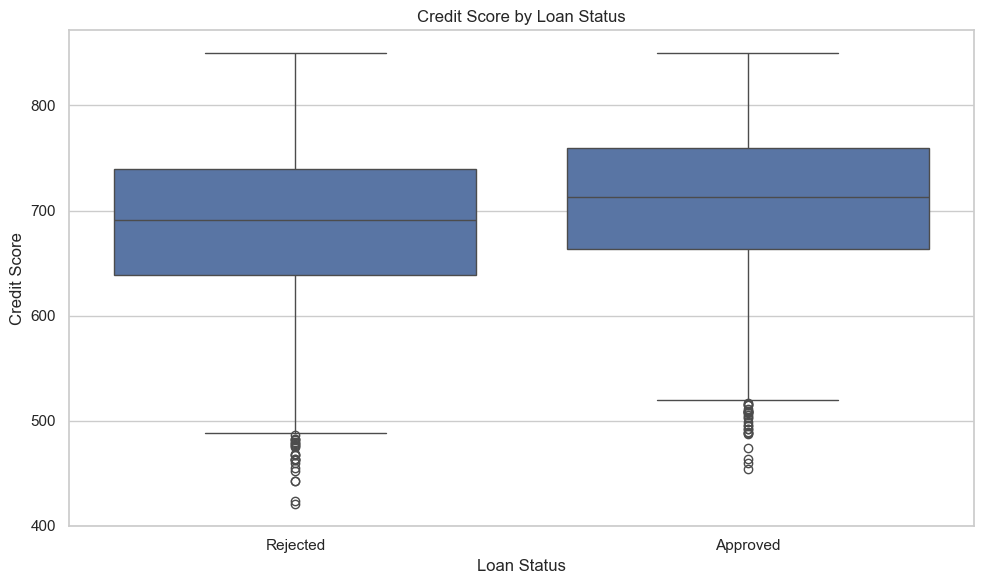

In [63]:
sns.boxplot(
    data=df, x="Loan_Status", y="Credit_score_cleaned"
)
plt.title("Credit Score by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Credit Score")
plt.tight_layout()
plt.show()

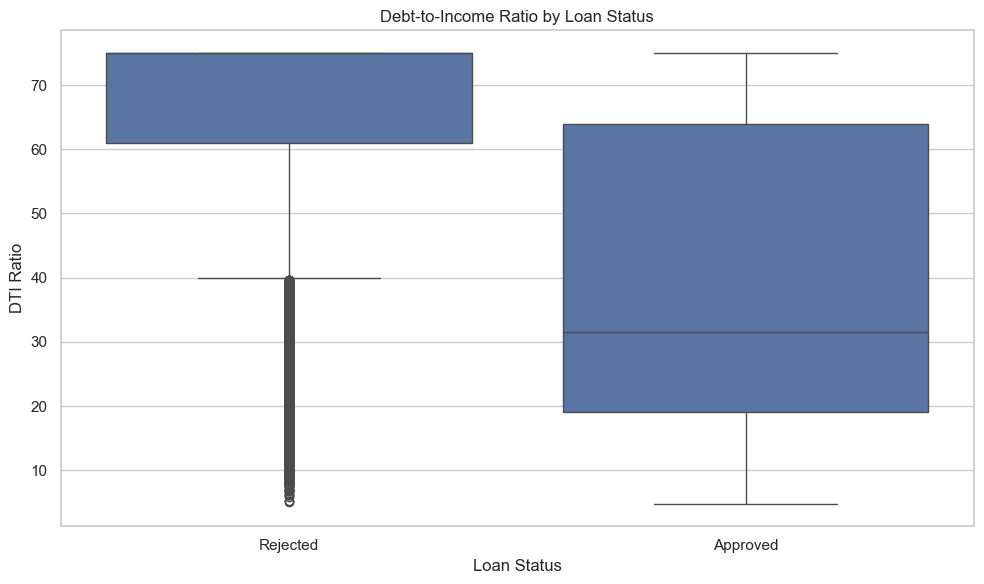

In [64]:
sns.boxplot(
    data=df, x="Loan_Status", y="DTI_Ratio"
)
plt.title("Debt-to-Income Ratio by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("DTI Ratio")
plt.tight_layout()
plt.show()

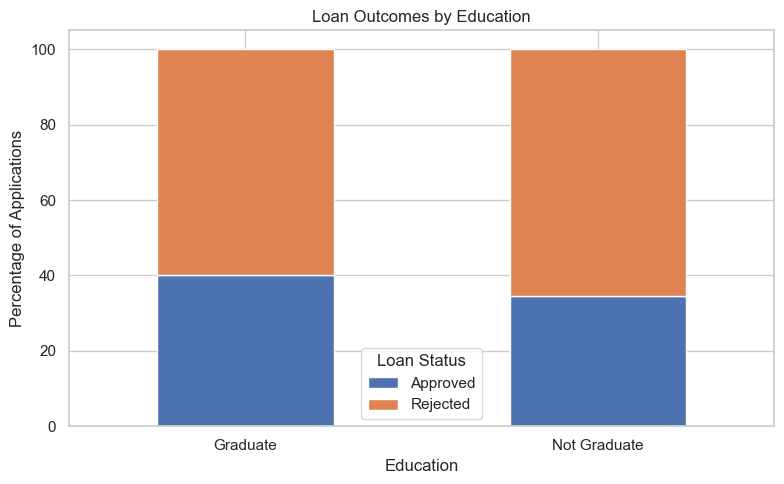

In [65]:
pd.crosstab(
    df["Education"], df["Loan_Status"], normalize="index"
).mul(100).plot(
    kind="bar", stacked=True, figsize=(8, 5)
)

plt.title("Loan Outcomes by Education")
plt.xlabel("Education")
plt.ylabel("Percentage of Applications")
plt.legend(title="Loan Status")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

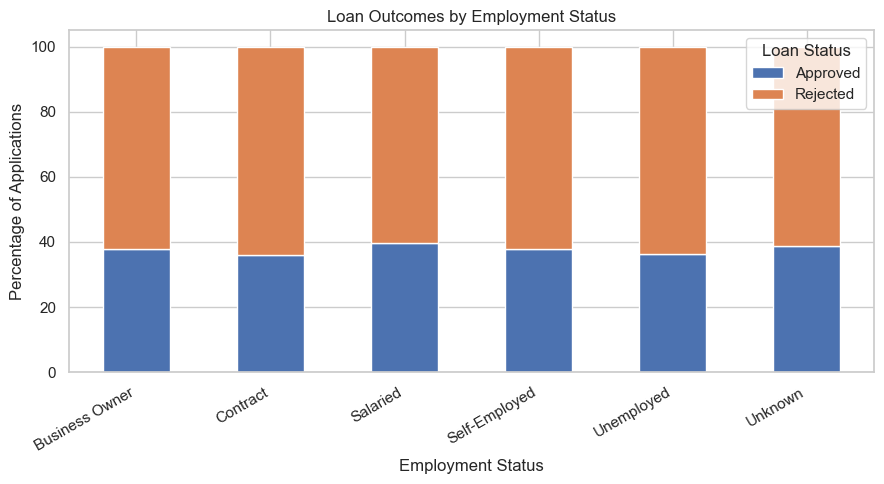

In [66]:
pd.crosstab(
    df["Employment_Status"], df["Loan_Status"], normalize="index"
).mul(100).plot(
    kind="bar", stacked=True, figsize=(9, 5)
)

plt.title("Loan Outcomes by Employment Status")
plt.xlabel("Employment Status")
plt.ylabel("Percentage of Applications")
plt.legend(title="Loan Status")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

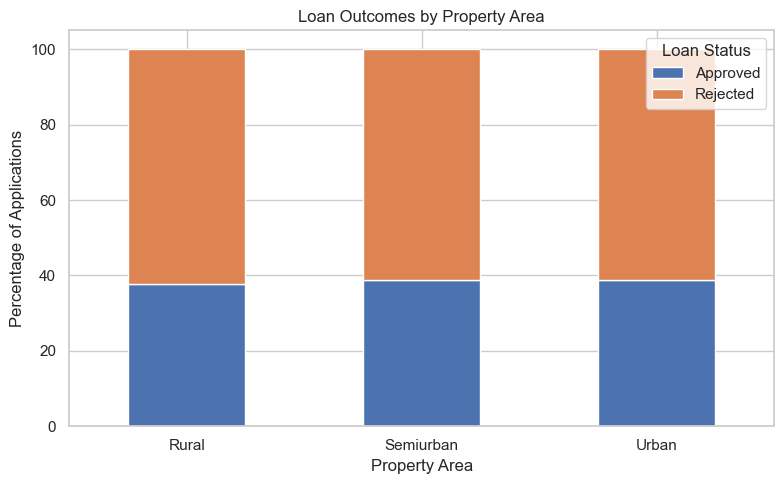

In [67]:
pd.crosstab(
    df["Property_area_cleaned"], df["Loan_Status"], normalize="index"
).mul(100).plot(
    kind="bar", stacked=True, figsize=(8, 5)
)

plt.title("Loan Outcomes by Property Area")
plt.xlabel("Property Area")
plt.ylabel("Percentage of Applications")
plt.legend(title="Loan Status")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

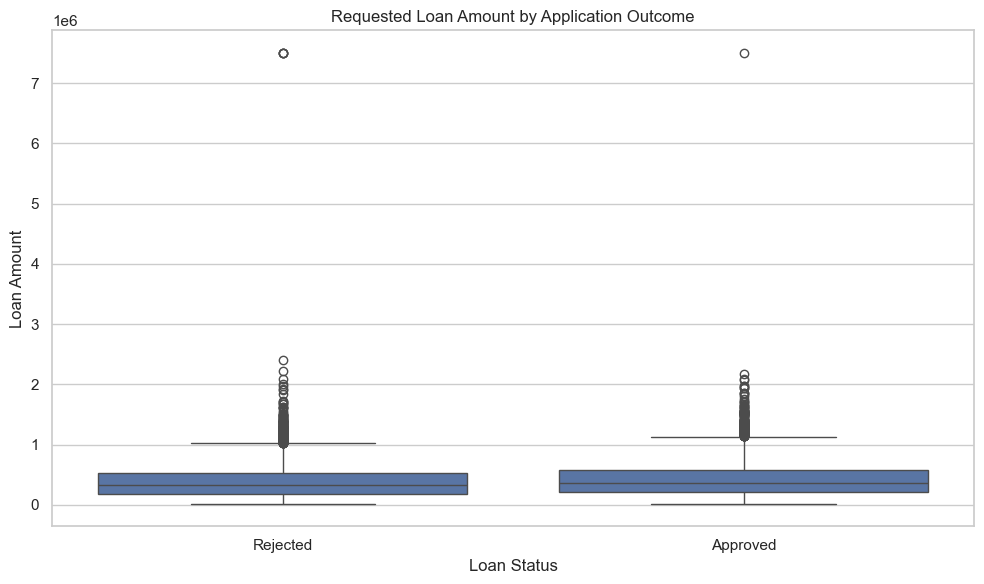

In [68]:
sns.boxplot(
    data=df,
    x="Loan_Status",
    y="Lone_Amount_Clean"
)

plt.title("Requested Loan Amount by Application Outcome")
plt.xlabel("Loan Status")
plt.ylabel("Loan Amount")
plt.tight_layout()
plt.show()

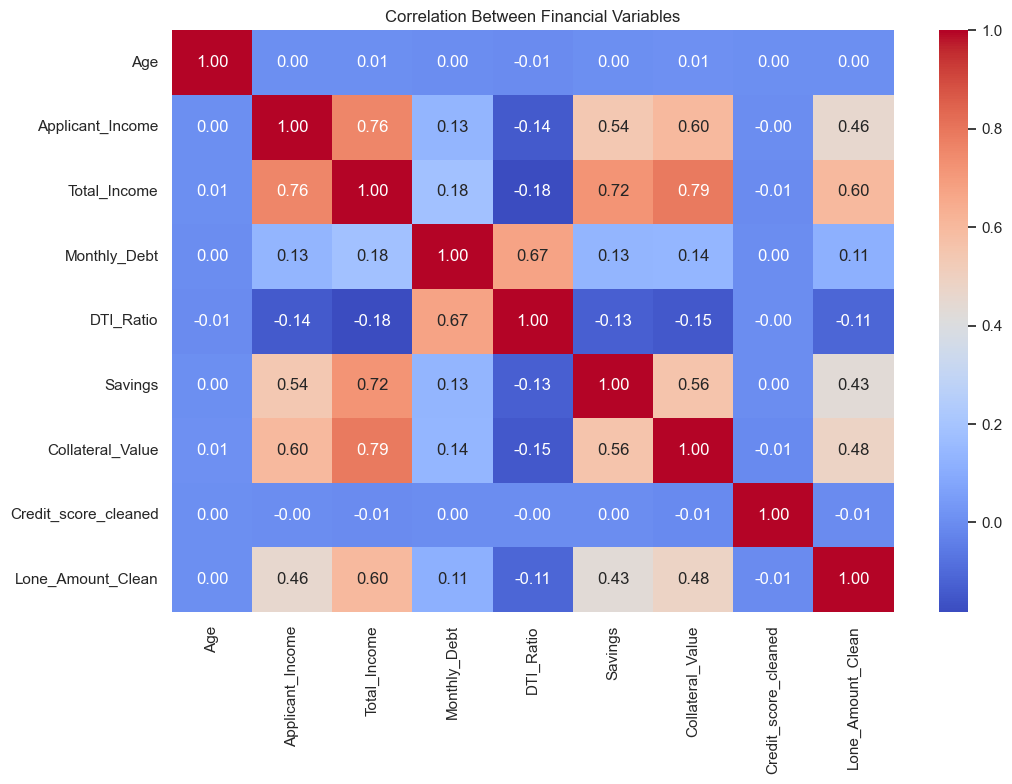

In [70]:
financial_cols = [
    "Age",
    "Applicant_Income",
    "Total_Income",
    "Monthly_Debt",
    "DTI_Ratio",
    "Savings",
    "Collateral_Value",
    "Credit_score_cleaned",
    "Lone_Amount_Clean"
]

plt.figure(figsize=(11, 8))

sns.heatmap(
    df[financial_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Between Financial Variables")
plt.tight_layout()
plt.show()

In [71]:
for col in [
    "Education",
    "Employment_Status",
    "Property_area_cleaned"
]:
    print(f"\nApproval rate by {col}:")
    print(
        (df.assign(
            Approved=df["Loan_Status"].str.lower().eq("approved")
        )
        .groupby(col, dropna=False)["Approved"]
        .mean()
        .mul(100)
        .round(2))
    )


Approval rate by Education:
Education
Graduate        40.08
Not Graduate    34.58
Name: Approved, dtype: float64

Approval rate by Employment_Status:
Employment_Status
Business Owner    37.69
Contract          36.13
Salaried          39.81
Self-Employed     37.69
Unemployed        36.16
Unknown           38.89
Name: Approved, dtype: float64

Approval rate by Property_area_cleaned:
Property_area_cleaned
Rural        37.73
Semiurban    38.82
Urban        38.73
Name: Approved, dtype: float64


In [72]:
print("Credit score by loan status:")
print(
    df.groupby("Loan_Status")["Credit_score_cleaned"]
      .mean()
      .round(2)
)

print("\nDTI ratio by loan status:")
print(
    df.groupby("Loan_Status")["DTI_Ratio"]
      .mean()
      .round(2)
)

Credit score by loan status:
Loan_Status
Approved    711.42
Rejected    689.50
Name: Credit_score_cleaned, dtype: float64

DTI ratio by loan status:
Loan_Status
Approved    38.95
Rejected    64.42
Name: DTI_Ratio, dtype: float64
